In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import atmosfera
import stella
import sensore

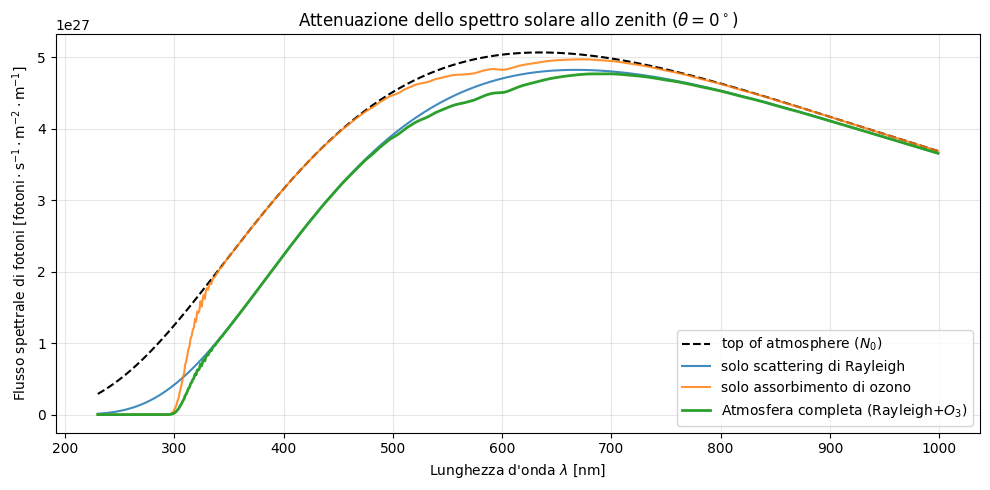

In [2]:
delta_lambda = 1e-9
wavelength = np.arange(230e-9, 1000e-9, delta_lambda)
sole = stella.CorpoNero('sole', 5778.0, 6.96e8, 1.496e11)
N0=sole.toa_flusso_fotoni(wavelength)

file_o3 = 'SCIA_O3_Temp_cross-section_V4.1.DAT'
atm_rayleigh =  atmosfera.Atmosfera(enable_rayleigh=True, enable_ozone=False)
atm_ozono = atmosfera.Atmosfera(enable_rayleigh=False, enable_ozone=True, percorso_file_O3 = file_o3)
atm_completa = atmosfera.Atmosfera(enable_rayleigh=True, enable_ozone=True, percorso_file_O3 = file_o3)

N_rayleigh = atm_rayleigh.N_obs(N0, wavelength, 0.0)
N_ozono = atm_ozono.N_obs(N0, wavelength, 0.0)
N_completa = atm_completa.N_obs(N0, wavelength, 0.0)

wl_nm=wavelength*1e9
plt.figure(figsize=(10,5))
plt.plot(wl_nm, N0, label="top of atmosphere ($N_0$)", color='black', linestyle='--')
plt.plot(wl_nm, N_rayleigh, label='solo scattering di Rayleigh', alpha=0.85)
plt.plot(wl_nm, N_ozono, label='solo assorbimento di ozono', alpha=0.85)
plt.plot(wl_nm, N_completa, label='Atmosfera completa (Rayleigh+$O_3$)', linewidth=2)
plt.xlabel("Lunghezza d'onda $\\lambda$ [nm]")
plt.ylabel("Flusso spettrale di fotoni [$\\mathrm{fotoni \\cdot s^{-1} \\cdot m^{-2} \\cdot m^{-1}}$]")
plt.title('Attenuazione dello spettro solare allo zenith ($\\theta = 0^\\circ$)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


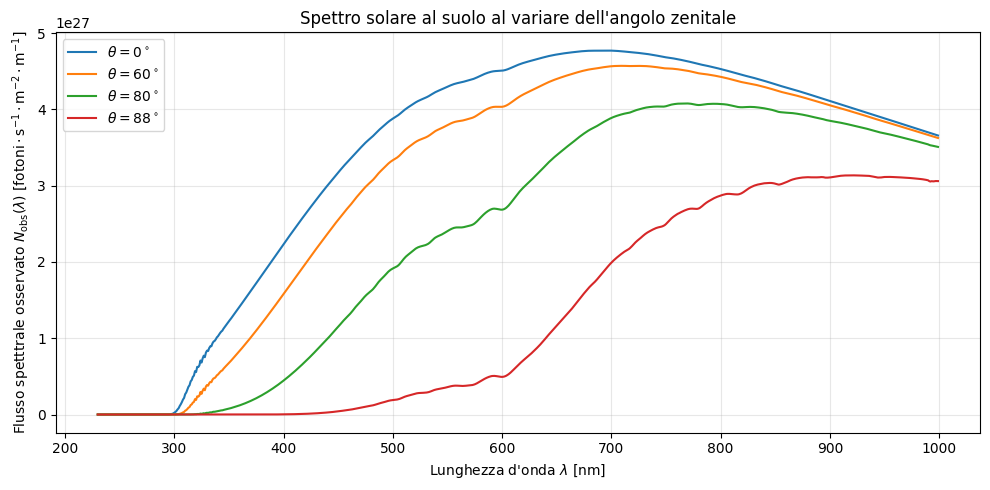

In [3]:
angoli = [0.0, 60.0, 80.0, 88.0]
plt.figure(figsize=(10,5))
for theta in angoli:
    N_theta = atm_completa.N_obs(N0, wavelength, theta)
    plt.plot(wl_nm, N_theta, label=f"$\\theta = {theta:.0f}^\\circ$")
plt.xlabel("Lunghezza d'onda $\\lambda$ [nm]")
plt.ylabel("Flusso spetttrale osservato $N_{\\mathrm{obs}}(\\lambda)$ [$\\mathrm{fotoni \\cdot s^{-1} \\cdot m^{-2} \\cdot m^{-1}}$]")
plt.title("Spettro solare al suolo al variare dell'angolo zenitale")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

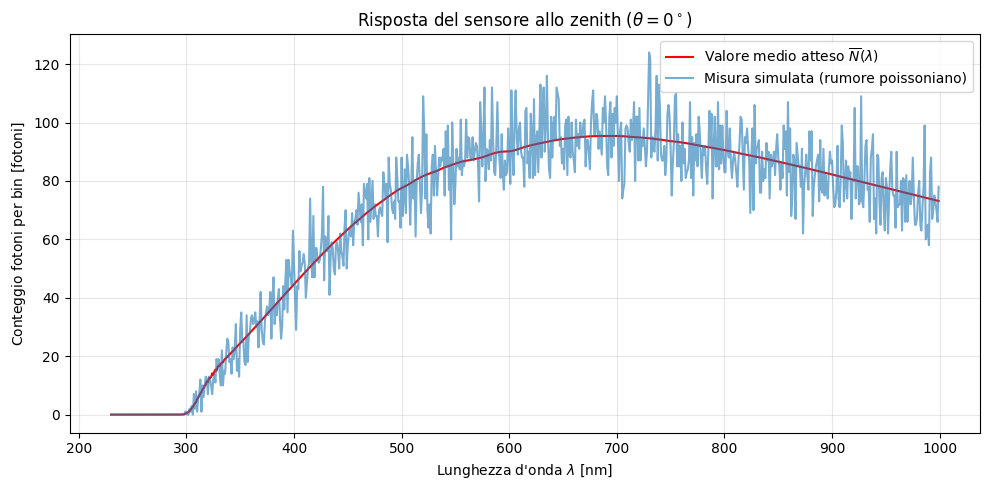

In [9]:
sensore_1 = sensore.sensore('sensore 1',area=1e-4, sensibilità=1.0, t_esposizione=2e-13, d_lambda=delta_lambda)
misurazione = sensore_1.misura(N_completa, wavelength)
plt.figure(figsize=(10,5))
plt.plot(wl_nm, misurazione['atteso'], label='Valore medio atteso $\\overline{N}(\\lambda)$', color='red', linewidth=1.5)
plt.plot(wl_nm, misurazione['misurato'], label='Misura simulata (rumore poissoniano)', alpha=0.6)
plt.xlabel("Lunghezza d'onda $\\lambda$ [nm]")
plt.ylabel('Conteggio fotoni per bin [$\\mathrm{fotoni}$]')
plt.title('Risposta del sensore allo zenith ($\\theta = 0^\\circ$)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

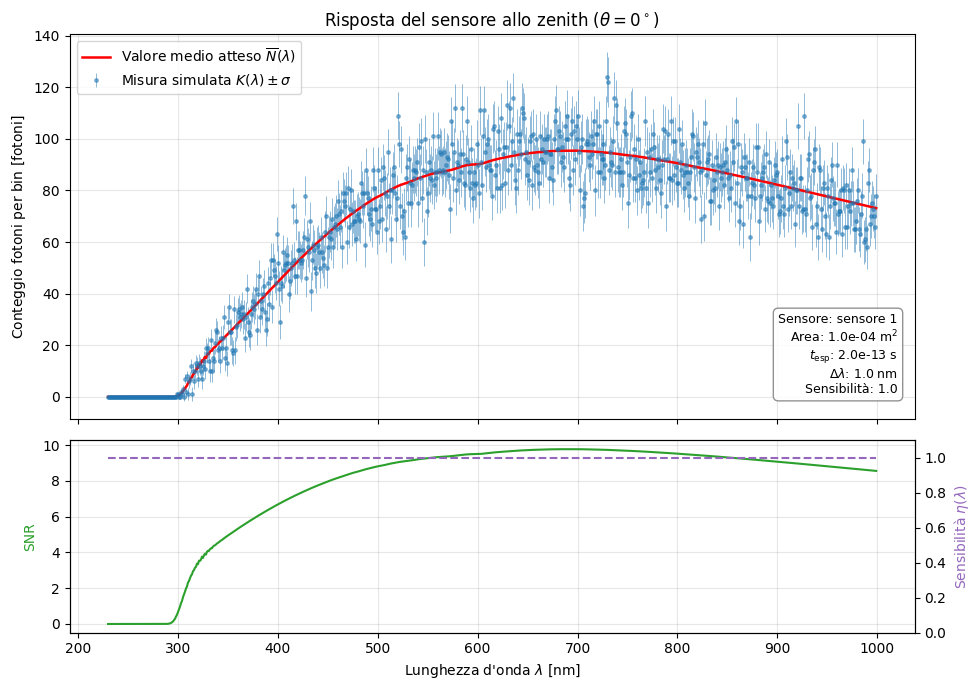

In [ ]:
eta_str = (
    "funzione $\\eta(\\lambda)$"
    if callable(sensore_1.sensibilità)
    else f"{sensore_1.sensibilità}"
)

info_sensore = (
    f"Sensore: {sensore_1.nome}\n"
    f"Area: {sensore_1.area:.1e} $\\mathrm{{m^2}}$\n"
    f"$t_{{\\mathrm{{esp}}}}$: {sensore_1.t_esposizione:.1e} s\n"
    f"$\\Delta\\lambda$: {sensore_1.d_lambda*1e9:.1f} nm\n"
    f"Sensibilità: {eta_str}"
)
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]}
)

ax1.errorbar(
    wl_nm, misurazione['misurato'], yerr=misurazione['incertezza'],
    fmt='o', markersize=2.5, elinewidth=0.7, alpha=0.5,
    label="Misura simulata $K(\\lambda) \\pm \\sigma$"
)
ax1.plot(wl_nm, misurazione['atteso'], label="Valore medio atteso $\\overline{N}(\\lambda)$", color="red", linewidth=1.8)
ax1.text(
    0.98, 0.06, info_sensore,
    transform=ax1.transAxes, fontsize=9, va="bottom", ha="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="gray", alpha=0.85)
)
ax1.set_ylabel("Conteggio fotoni per bin [$\\mathrm{fotoni}$]")
ax1.set_title("Risposta del sensore allo zenith ($\\theta = 0^\\circ$)")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)


ax2.plot(wl_nm, misurazione['SNR'], color="tab:green", label="SNR $(\\overline{N} / \\sigma)$")
ax2.set_xlabel("Lunghezza d'onda $\\lambda$ [nm]")
ax2.set_ylabel("SNR", color="tab:green")
ax2.grid(True, alpha=0.3)

ax2_eta = ax2.twinx()
ax2_eta.plot(wl_nm, sensore_1.sens(wavelength), color="tab:purple", linestyle="--", label="Sensibilità $\\eta(\\lambda)$")
ax2_eta.set_ylabel("Sensibilità $\\eta(\\lambda)$", color="tab:purple")
ax2_eta.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()